# 1. Componentes del simulador

Este notebook muestra cada parte del proyecto por separado, en el orden en que se arma una simulación. No entrena nada y no necesita resultados guardados.

| Sección | Archivo |
|---|---|
| 1. Mapas | `conduccion/mapa/mapa.py` |
| 2. Rutas y puntos de control | `conduccion/mapa/ruta.py` |
| 3. Física del auto | `conduccion/auto/auto.py` |
| 4. Sensores | `conduccion/auto/sensores.py` |
| 5. Perceptrón multicapa | `conduccion/aprendizaje/perceptron_multicapa.py` |
| 6. Episodio y aptitud | `conduccion/simulacion/simulacion.py`, `conduccion/aprendizaje/fitness.py` |
| 7. Selección, cruce y mutación | `conduccion/aprendizaje/genetico.py` |

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))     # la carpeta del proyecto

import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

from conduccion import config
from conduccion.aprendizaje.fitness import nota_de_ruta
from conduccion.aprendizaje.genetico import cruzar, mutar, poblacion_inicial, seleccion
from conduccion.aprendizaje.perceptron_multicapa import Perceptron, cantidad_de_pesos
from conduccion.auto.auto import Auto
from conduccion.auto.sensores import Sensores
from conduccion.mapa.mapa import manzana, santa_fe
from conduccion.mapa.ruta import ruta_al_azar, vueltas_a_la_manzana
from conduccion.parametros import usar_parametros, volver_a_config
from conduccion.simulacion.simulacion import correr_episodio
from conduccion.visualizacion.graficos import (AZUL, DIVERGENTE, NARANJA, NOMBRES_ENTRADAS, SERIES, aplicar_estilo,
                                               dibujar_auto, dibujar_mapa, dibujar_rayos, dibujar_recorrido,
                                               dibujar_ruta)

aplicar_estilo()
volver_a_config()

## 1. Mapas

Los mapas son calles reales de Santa Fe, bajadas de OpenStreetMap con osmnx y guardadas en `mapas/`. No hace falta internet para usarlos. Todas las calles se tratan como doble mano.

Un mapa es un grafo: las esquinas son los nodos y las cuadras son las aristas. Cada cuadra se ensancha un carril a cada lado, y la unión de esas franjas es la superficie de la calle. Esa superficie se guarda también como una matriz de celdas de 0,25 m, porque consultarla es más rápido que preguntarle a shapely.

| Zona | Qué es | Uso |
|---|---|---|
| `manzana()` | la manzana del medio del 3×3 | primera etapa |
| `santa_fe("2x2")`, `santa_fe("3x3")` | grillas de 2×2 y 3×3 manzanas del centro | etapas 2 y 3 |
| `santa_fe("centro")` | 500 m alrededor de la Plaza 25 de Mayo, con diagonales y una avenida curva | prueba (en el informe no es una etapa) |
| `santa_fe("guadalupe")` | un barrio que la red no ve al entrenar | prueba |
| `santa_fe("n1_01_...")`, ... | 58 recortes de 1 km de toda la ciudad, de donde salen los barrios de prueba | evaluación |

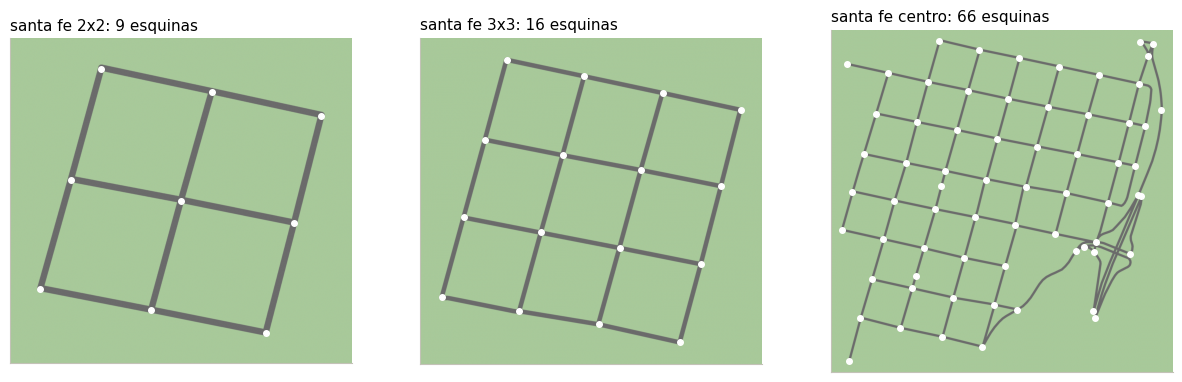

In [2]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 5))
for ax, zona in zip(ejes, ("2x2", "3x3", "centro")):
    mapa = santa_fe(zona)
    dibujar_mapa(ax, mapa)
    ax.set_title(mapa.nombre + ": " + str(mapa.grafo.number_of_nodes()) + " esquinas")
plt.show()

## 2. Rutas y puntos de control

Una ruta va de una esquina A a otra esquina B:

1. A\* (networkx) busca el camino más corto entre las dos esquinas.
2. shapely une las cuadras del camino y corre esa línea medio carril a la derecha: ese es el carril que el auto tiene que seguir.
3. Sobre el carril se ponen puntos de control cada 10 m, y uno más en cada giro. El último punto es B.

El entrenamiento descarta las rutas de menos de 150 m.

Largo: 246.9 m | puntos de control: 25 | esquinas: 3


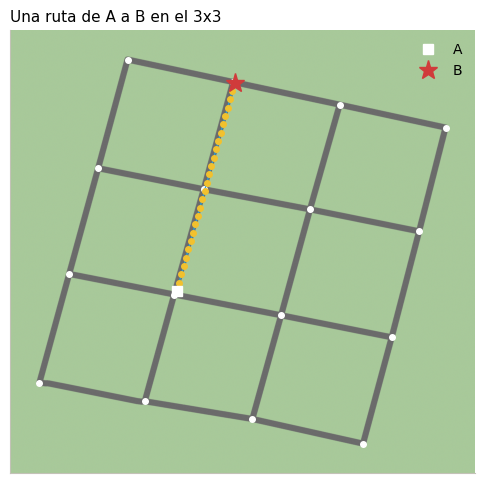

In [3]:
mapa = santa_fe("3x3")
ruta = ruta_al_azar(mapa, np.random.default_rng(1))
print("Largo:", round(ruta.largo, 1), "m | puntos de control:", len(ruta.puntos), "| esquinas:", len(ruta.esquinas))

fig, ax = plt.subplots(figsize=(6, 6))
dibujar_mapa(ax, mapa)
dibujar_ruta(ax, ruta)
ax.legend(loc="upper right")
ax.set_title("Una ruta de A a B en el 3x3")
plt.show()

### La manzana

La primera etapa del entrenamiento es dar la vuelta a una manzana. Se usa la manzana del medio del 3×3 porque sus cuatro esquinas son cruces completos. Desde cada esquina hay dos vueltas: una doblando siempre a la izquierda y otra siempre a la derecha. En total son 8 vueltas.

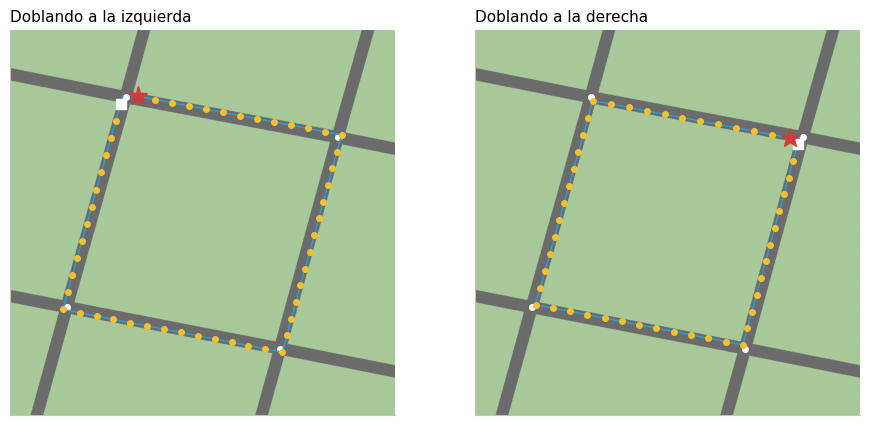

In [4]:
mapa_manzana = manzana()
izquierda, derecha = vueltas_a_la_manzana(mapa_manzana)

fig, ejes = plt.subplots(1, 2, figsize=(11, 5))
for ax, vuelta, titulo in ((ejes[0], izquierda[0], "Doblando a la izquierda"), (ejes[1], derecha[0], "Doblando a la derecha")):
    dibujar_mapa(ax, mapa_manzana)
    dibujar_ruta(ax, vuelta)
    centro = np.mean([mapa_manzana.posicion(e) for e in mapa_manzana.esquinas_manzana], axis=0)
    ax.set_xlim(centro[0] - 110, centro[0] + 110)
    ax.set_ylim(centro[1] - 110, centro[1] + 110)
    ax.set_title(titulo)
plt.show()

## 3. Física del auto

El auto se mueve con el **modelo de bicicleta cinemático** de Kong et al. (2015): las dos ruedas de cada eje se juntan en una sola, y solo gira la delantera. La red decide el ángulo del volante $\delta$ y la aceleración $a$, que son justo las dos entradas del modelo.

$$\beta = \arctan\!\left(\frac{l_r}{l_f + l_r}\,\tan\delta\right)$$

$$\dot{x} = v\cos(\psi + \beta) \qquad \dot{y} = v\sin(\psi + \beta) \qquad \dot{\psi} = \frac{v}{l_r}\,\sin\beta \qquad \dot{v} = a$$

Cada paso de $\Delta t = 0{,}1$ s se integra con Euler: cada variable suma su derivada por $\Delta t$.

| Símbolo | Qué es | En el código | Valor |
|---|---|---|---|
| $x, y$ | posición del centro de masa | `auto.x`, `auto.y` | |
| $\psi$ | hacia dónde mira el auto | `auto.angulo` | |
| $v$ | velocidad | `auto.velocidad` | 0 a 11 m/s |
| $\delta$ | ángulo del volante | `volante` | −35° a 35° |
| $a$ | aceleración (negativa = freno) | `aceleracion` | −4 a 2 m/s² |
| $l_f$, $l_r$ | del centro de masa a cada eje | `L_F`, `L_R` | 1,1 m y 1,7 m |

**Límite de agarre.** El modelo cinemático deja doblar a cualquier velocidad. Para que el auto tenga que frenar antes de un giro, la aceleración lateral $a_y = v^2 \sin\beta / l_r$ se limita a `ACELERACION_LATERAL_MAXIMA`. A mayor velocidad, menos volante disponible.

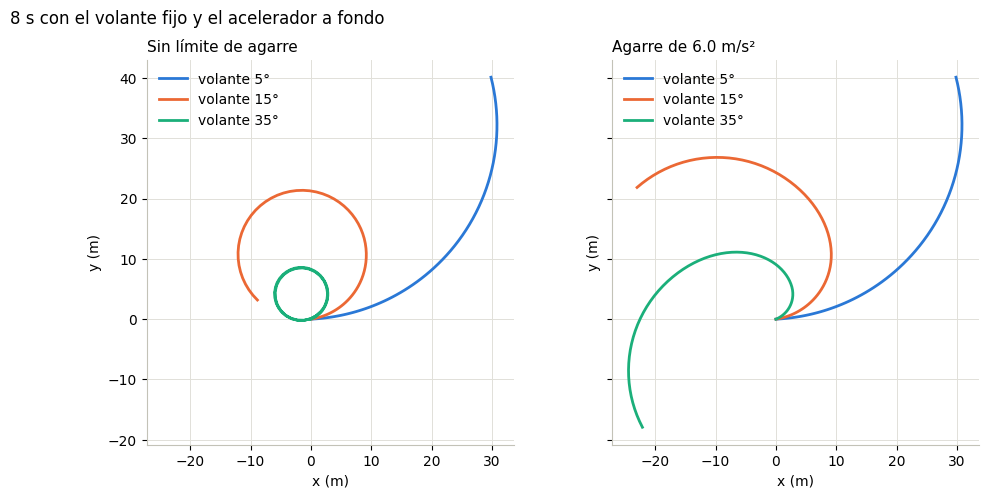

In [5]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
for ax, agarre in zip(ejes, (None, 6.0)):
    usar_parametros(ACELERACION_LATERAL_MAXIMA=agarre)
    for grados, color in zip((5, 15, 35), SERIES):
        auto = Auto(0, 0, 0)
        recorrido = [(auto.x, auto.y)]
        for _ in range(int(8 / config.DT)):
            auto.avanzar(math.radians(grados), config.ACELERACION_MAXIMA)
            recorrido.append((auto.x, auto.y))
        ax.plot(*zip(*recorrido), color=color, label="volante " + str(grados) + "°")
    ax.set_aspect("equal")
    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")
    ax.set_title("Sin límite de agarre" if agarre is None else "Agarre de " + str(agarre) + " m/s²")
    ax.legend()
volver_a_config()
plt.suptitle("8 s con el volante fijo y el acelerador a fondo", x=0.01, ha="left")
plt.show()

Sin límite, el auto dobla cerrado aunque vaya rápido. Con el límite, a medida que acelera el giro se abre.

## 4. Sensores

El auto no sabe dónde está en el mapa: solo ve lo que miden sus sensores. Con eso arma las 16 entradas de la red.

| Entradas | Cantidad | Cómo se calcula | Rango |
|---|---|---|---|
| Rayos al borde de la calle | 7 | distancia / 30 m, a −90°, −60°, ..., 90° | 0 a 1 |
| Velocidad | 1 | $v$ / 11 m/s | 0 a 1 |
| Brújula al próximo punto | 2 | seno y coseno del ángulo al punto | −1 a 1 |
| Distancia al próximo punto | 1 | distancia / 10 m, hasta 1 | 0 a 1 |
| Desvío del carril | 1 | distancia con signo a la línea del carril / 3,5 m | −1 a 1 |
| Miradas al carril | 4 | seno y coseno de la dirección a un punto del carril 3 m y 6 m adelante | −1 a 1 |

La brújula entra como seno y coseno, y no como ángulo, para que no haya un salto de 180° a −180°. Durante el entrenamiento se suma a cada entrada un ruido normal de desvío 0,02.

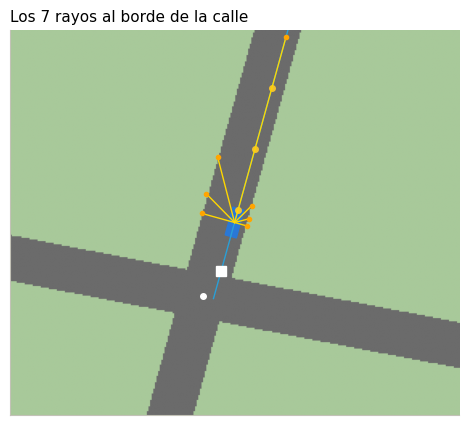

entrada,rayo -90°,rayo -60°,rayo -30°,rayo 0°,rayo 30°,rayo 60°,rayo 90°,velocidad,brújula seno,brújula coseno,distancia al punto,desvío del carril,carril a 3 m seno,carril a 3 m coseno,carril a 6 m seno,carril a 6 m coseno
valor,0.067,0.075,0.125,1.0,0.35,0.208,0.175,0.364,-0.0,1.0,1.0,0.0,-0.0,1.0,-0.0,1.0


In [6]:
x0, y0, angulo0 = ruta.inicio
auto = Auto(x0, y0, angulo0)
for _ in range(40):                 # unos metros hacia adelante
    auto.avanzar(0, 1.0)
entradas = Sensores(mapa, ruta.carril).entradas(auto, ruta.puntos[3])

fig, ax = plt.subplots(figsize=(6, 5))
dibujar_mapa(ax, mapa)
dibujar_ruta(ax, ruta)
dibujar_rayos(ax, auto, mapa)
dibujar_auto(ax, auto)
ax.set_xlim(auto.x - 35, auto.x + 35)
ax.set_ylim(auto.y - 30, auto.y + 30)
ax.set_title("Los 7 rayos al borde de la calle")
plt.show()

pd.DataFrame({"entrada": NOMBRES_ENTRADAS, "valor": np.round(entradas, 3)}).set_index("entrada").T

## 5. Perceptrón multicapa

16 entradas, una capa oculta de 16 neuronas y 2 salidas, todas con tangente hiperbólica. La primera salida es el volante y la segunda, el acelerador (negativa = freno).

La red no se entrena con retropropagación: sus pesos los busca el algoritmo genético. Por eso todos los pesos y umbrales, puestos en fila, forman el **cromosoma** del individuo.

In [7]:
red = Perceptron(config.CAPAS, np.random.default_rng(0))
print("Capas:", config.CAPAS)
print("Largo del cromosoma: 16·16 + 16 + 16·2 + 2 =", cantidad_de_pesos(config.CAPAS))
print("Salidas para las entradas de arriba (volante, acelerador):", np.round(red.propagar(entradas), 3))

Capas: [16, 16, 2]
Largo del cromosoma: 16·16 + 16 + 16·2 + 2 = 306
Salidas para las entradas de arriba (volante, acelerador): [ 0.086 -0.088]


## 6. Episodio y aptitud

En un episodio la red maneja una ruta hasta que llega a B, choca (alguna esquina del auto sale de la calle) o se le acaba el tiempo. La nota de una ruta es:

$$F_r = \frac{k + p}{K}\,\big(1 - c \cdot f_{\text{fuera}}\big)$$

- $k$: puntos de control pasados, en orden. Si el auto pasa lejos de un punto pero alcanza uno de los dos siguientes, los salteados también cuentan. $K$: total de puntos.
- $p$: progreso hacia el siguiente punto, de 0 a 1.
- $f_{\text{fuera}}$: fracción del tiempo con alguna esquina fuera del carril; $c = 0{,}8$.

La aptitud de un individuo es el promedio de $F_r$ sobre las rutas de la generación. Vale 1 si llega a B sin salir de su carril.

Acá manejan 5 redes con pesos al azar.

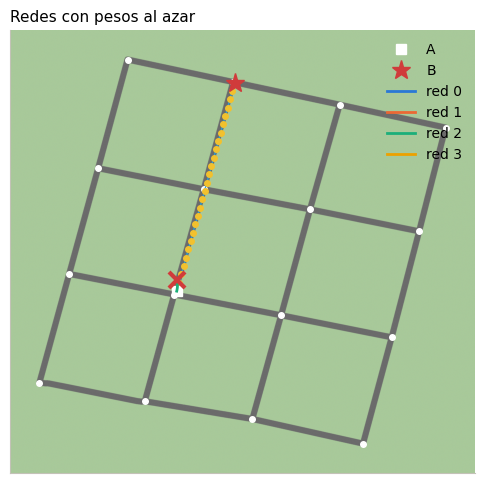

,termina por,puntos,nota
red,,,
0,tiempo,0 de 25,0.000
1,tiempo,0 de 25,0.000
2,choque,1 de 25,0.037
3,tiempo,0 de 25,0.000


In [8]:
fig, ax = plt.subplots(figsize=(6, 6))
dibujar_mapa(ax, mapa)
dibujar_ruta(ax, ruta)
filas = []
for semilla, color in zip(range(4), SERIES):
    red_al_azar = Perceptron(config.CAPAS, np.random.default_rng(semilla))
    resultado = correr_episodio(mapa, ruta, red_al_azar)
    dibujar_recorrido(ax, resultado, color=color, etiqueta="red " + str(semilla))
    filas.append({"red": semilla, "termina por": resultado.motivo,
                  "puntos": str(resultado.puntos_alcanzados) + " de " + str(resultado.total_puntos),
                  "nota": round(nota_de_ruta(resultado), 3)})
ax.legend(loc="upper right")
ax.set_title("Redes con pesos al azar")
plt.show()
pd.DataFrame(filas).set_index("red")

## 7. Selección, cruce y mutación

Cada generación nueva se arma así:

1. **Elitismo:** los 2 mejores pasan sin cambios.
2. **Selección por torneo:** se eligen 3 individuos al azar y gana el de mayor nota. Se hace un torneo para el padre y otro para la madre.
3. **Cruce**, con probabilidad 0,8. Si no hay cruce, el hijo es una copia del padre.
4. **Mutación** del hijo.

### Selección

Se corren 20.000 torneos con `seleccion`, en una población de 50 individuos ordenados por nota. El peor nunca gana, y el mejor no siempre participa.

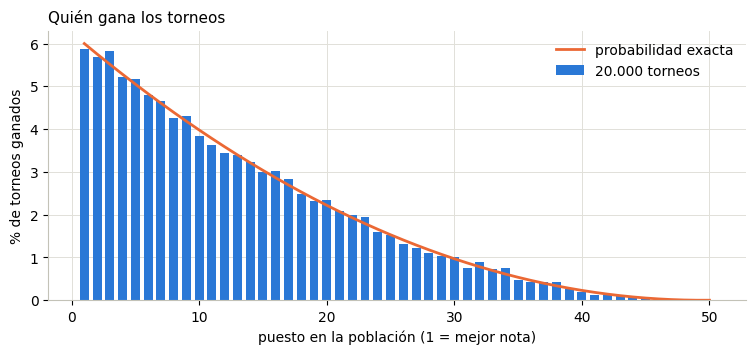

In [9]:
rng = np.random.default_rng(0)
N = 50
poblacion = [np.array([k]) for k in range(N)]       # cada individuo es solo su puesto: 0 es el mejor
notas = np.linspace(1, 0, N)
victorias = np.zeros(N)
for _ in range(20000):
    victorias[seleccion(poblacion, notas, rng)[0]] += 1

t = config.TAMANO_TORNEO
exacto = [math.comb(N - 1 - k, t - 1) / math.comb(N, t) for k in range(N)]

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(np.arange(1, N + 1), 100 * victorias / victorias.sum(), color=AZUL, width=0.7, label="20.000 torneos")
ax.plot(np.arange(1, N + 1), 100 * np.array(exacto), color=NARANJA, label="probabilidad exacta")
ax.set_xlabel("puesto en la población (1 = mejor nota)")
ax.set_ylabel("% de torneos ganados")
ax.set_title("Quién gana los torneos")
ax.legend()
plt.show()

### Cruce

| `TIPO_CRUCE` | Qué hace |
|---|---|
| `"neurona"` | cada neurona del hijo copia de un solo padre todos sus pesos de entrada y su umbral (Montana y Davis, 1989) |
| `"pesos"` | cada peso se copia del padre o de la madre, al azar |
| `"blx"` | BLX-α: cada peso se sortea en el intervalo entre los dos padres, agrandado α = 0,5 a cada lado |
| `"ninguna"` | sin cruce: el hijo es una copia del padre |

El gráfico muestra los pesos de entrada a la capa oculta del hijo. Cada columna es una neurona y cada fila, una entrada. El color dice de qué padre viene cada peso: el cruce por neurona deja columnas enteras de un solo color.

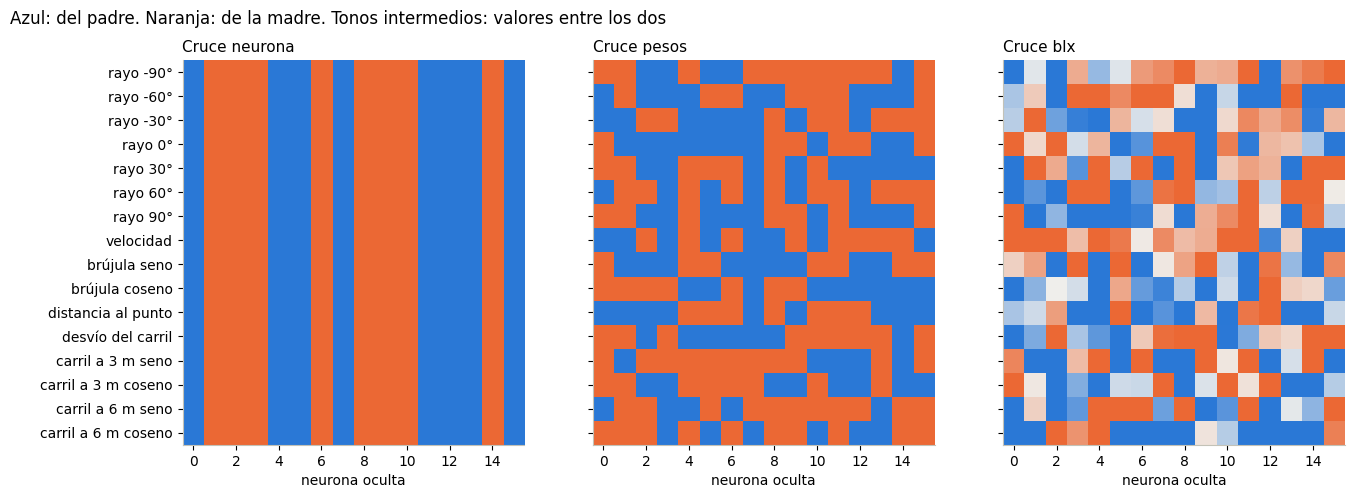

In [10]:
usar_parametros(PROBABILIDAD_CRUCE=1.0)             # para que siempre haya cruce
rng = np.random.default_rng(3)
padre, madre = poblacion_inicial(2, config.CAPAS, rng)
de_padre_a_madre = LinearSegmentedColormap.from_list("padres", [AZUL, "#f0efec", NARANJA])

fig, ejes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
for ax, tipo in zip(ejes, ("neurona", "pesos", "blx")):
    hijo = cruzar(padre, madre, config.CAPAS, tipo, rng)
    fraccion = (hijo - padre) / (madre - padre)     # 0 = como el padre, 1 = como la madre
    capa_oculta = Perceptron(config.CAPAS, cromosoma=fraccion).pesos[0]
    ax.imshow(capa_oculta, cmap=de_padre_a_madre, vmin=0, vmax=1, aspect="auto")
    ax.grid(False)
    ax.set_title("Cruce " + tipo)
    ax.set_xlabel("neurona oculta")
ejes[0].set_yticks(range(len(NOMBRES_ENTRADAS)), NOMBRES_ENTRADAS)
volver_a_config()
plt.suptitle("Azul: del padre. Naranja: de la madre. Tonos intermedios: valores entre los dos", x=0.01, ha="left")
plt.show()

### Mutación

| `TIPO_MUTACION` | Qué hace |
|---|---|
| `"gaussiana"` | a cada gen, con probabilidad 0,05, se le suma un valor normal de desvío σ |
| `"neurona"` | se eligen 2 neuronas y se les suma ese ruido a todos sus pesos de entrada y a su umbral |

En la gaussiana los cambios quedan salpicados por toda la red. En la de neurona se ven columnas completas.

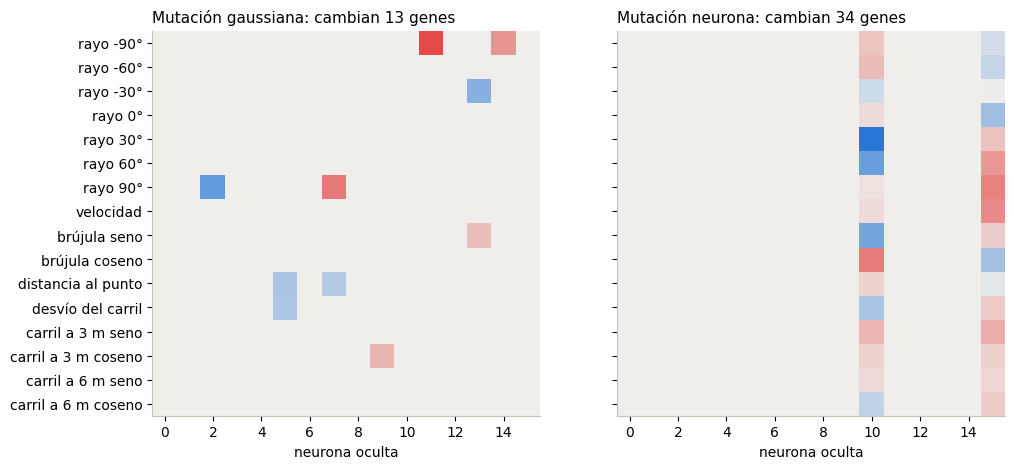

In [11]:
rng = np.random.default_rng(1)
original = poblacion_inicial(1, config.CAPAS, rng)[0]

fig, ejes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
for ax, tipo in zip(ejes, ("gaussiana", "neurona")):
    mutado = mutar(original, config.CAPAS, config.SIGMA, tipo, rng)
    cambio = Perceptron(config.CAPAS, cromosoma=mutado - original).pesos[0]
    limite = max(abs(cambio).max(), 1e-9)
    ax.imshow(cambio, cmap=DIVERGENTE, vmin=-limite, vmax=limite, aspect="auto")
    ax.grid(False)
    ax.set_title("Mutación " + tipo + ": cambian " + str(int((mutado != original).sum())) + " genes")
    ax.set_xlabel("neurona oculta")
ejes[0].set_yticks(range(len(NOMBRES_ENTRADAS)), NOMBRES_ENTRADAS)
plt.show()